# Assignment 2

**Karl Savinskiy**  
**CSc 44700, Fall 2026**

## Goal

In this assignment, I compared how well different combinations of Iris measurements distinguish Versicolor from Virginica. I used all 100 flowers from these two species, with 50 from each, and left out Setosa. As instructed, I used the same data for training and calculating accuracy, without a train/test split.

There are four measurements, which I labeled as follows:

| Letter | Feature |
| --- | --- |
| A | Sepal length |
| B | Sepal width |
| C | Petal length |
| D | Petal width |

The measurements are in centimeters. I tried all 15 possible nonempty combinations: four single features, six pairs, four triples, and all four features together.


In [11]:
# author: Karl Savinskiy
# CSc 44700, Assignment 2
# Based on the class example by Erik K. Grimmelmann

from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler

# load the Iris data
iris = datasets.load_iris()
# keep versicolor and virginica
X = iris.data[iris.target != 0]
y = iris.target[iris.target != 0]

letters = "ABCD"
for i in range(4):
    print(letters[i], "=", iris.feature_names[i])

print("Versicolor:", np.sum(y == 1))
print("Virginica:", np.sum(y == 2))

A = sepal length (cm)
B = sepal width (cm)
C = petal length (cm)
D = petal width (cm)
Versicolor: 50
Virginica: 50


## Method

I followed the fit-and-score approach shown in Lecture 6 and the supplied example notebook. For each feature combination, I created a new `SGDClassifier`, trained it with `.fit()`, and calculated its training accuracy with `.score()`.

I chose `log_loss`, which gives a logistic regression classifier trained using SGD. The loss measures how well the model's predictions match the labels, and training updates the weights to reduce it. I also used L2 regularization, which penalizes large weights, as discussed in Lecture 9.

Before training, I used `StandardScaler` to subtract each feature's mean and divide by its standard deviation. This puts the features on similar scales and helps the gradient descent process. This preprocessing step goes beyond the basic lecture example. Each column is scaled separately using the 100 training flowers.

I kept the settings the same for every combination so that the comparison focused on the features:

| Setting | Value |
| --- | --- |
| Loss | log_loss |
| Penalty | l2 |
| Regularization strength (`alpha`) | 0.0001 |
| Learning rate schedule | adaptive |
| Starting learning rate (`eta0`) | 0.01 |
| Maximum epochs (`max_iter`) | 10000 |
| Stopping tolerance (`tol`) | 0.000001 |
| Random seed (`random_state`) | 28 |

The adaptive learning rate gets smaller when training loss stops improving enough. The epoch limit allows up to 10000 passes through the data, but training can stop earlier. The fixed random seed makes the runs repeatable in the same environment.

The accuracy is the number of correctly classified flowers divided by the total number of flowers. Since there are 100 flowers, an accuracy of 94% means that 94 were classified correctly and six were misclassified.


In [ ]:
# scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# try all 15 feature combinations
results = []
for number_of_features in range(1, 5):
    for columns in combinations(range(4), number_of_features):
        XX = X_scaled[:, columns]

        clf = SGDClassifier(
            loss="log_loss", penalty="l2", alpha=0.0001,
            learning_rate="adaptive", eta0=0.01,
            max_iter=10000, tol=1e-6, random_state=28
        )
        # fit and score using all 100 flowers
        clf.fit(XX, y)
        accuracy = clf.score(XX, y) * 100

        label = "".join(letters[i] for i in columns)
        results.append([label, accuracy])

results = pd.DataFrame(results, columns=["Features", "Training accuracy (%)"])
display(results.round(1))

,Features,Training accuracy (%)
0,A,73.0
1,B,58.0
2,C,93.0
3,D,94.0
4,AB,75.0
5,AC,95.0
6,AD,94.0
7,BC,93.0
8,BD,93.0
9,CD,94.0


## Results

The table above lists the accuracy for each combination. The bar chart shows the same results, starting with single features and ending with all four features.


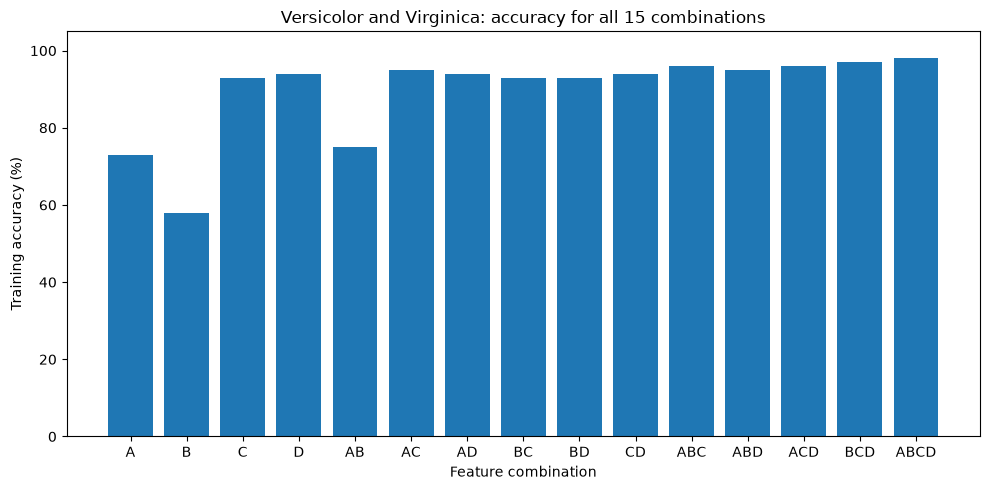

In [13]:
# compare the training accuracies
plt.figure(figsize=(10, 5))
plt.bar(results["Features"], results["Training accuracy (%)"])
plt.xlabel("Feature combination")
plt.ylabel("Training accuracy (%)")
plt.title("Versicolor and Virginica: accuracy for all 15 combinations")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

## Comparing the measurements

These scatter plots show the two sepal measurements (AB) and the two petal measurements (CD). The colors and markers indicate the actual species of each flower.


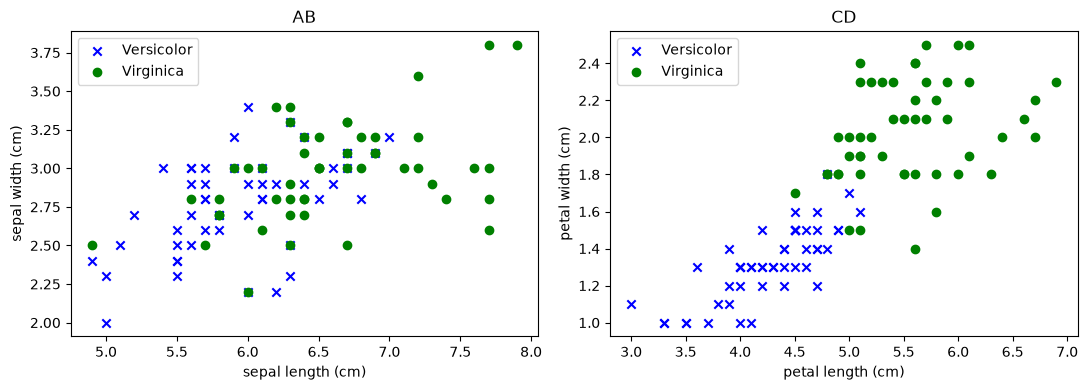

In [14]:
# plot sepal and petal measurements
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, columns in zip(axes, [(0, 1), (2, 3)]):
    first, second = columns
    ax.scatter(X[y == 1, first], X[y == 1, second],
               color="blue", marker="x", label="Versicolor")
    ax.scatter(X[y == 2, first], X[y == 2, second],
               color="green", marker="o", label="Virginica")
    ax.set_xlabel(iris.feature_names[first])
    ax.set_ylabel(iris.feature_names[second])
    ax.set_title(letters[first] + letters[second])
    ax.legend()

plt.tight_layout()
plt.show()

## Discussion

The petal measurements worked better on their own than the sepal measurements. Petal length (C) gave 93% accuracy and petal width (D) gave 94%. Sepal length (A) gave 73%, and sepal width (B) gave 58%. The scatter plots help explain this difference: the two species overlap much more when plotted using the sepal measurements. The petal plot separates them more clearly, although there is still some overlap.

The best pair was AC, with 95% accuracy. AB gave only 75%, while CD gave 94%. This shows that a feature that performs poorly alone can still be useful when combined with another feature. In this case, adding sepal length to petal length increased accuracy from 93% to 95%.

For three features, BCD had the highest accuracy at 97%. ABC and ACD both gave 96%, and ABD gave 95%. Using all four features gave the best result overall: 98%, or 98 correctly classified flowers out of 100.

Adding more features did not improve every result. For example, D alone gave 94%, but adding B reduced the accuracy to 93%. Also, C and BC both gave 93%. One reason an improvement is not guaranteed is that training minimizes the regularized loss, rather than directly maximizing the number of correct classifications. Adding a feature changes the fitted weights and can move the decision boundary.

Overall, petal measurements were the strongest individual features in this experiment, and all four measurements together gave the highest training accuracy with these settings. These are training scores because the assignment required using all the data for training. They show how well the models fit these flowers, but they do not measure performance on new flowers.

## References

- Assignment 2 instructions.
- ML 06 Adaline and the supplied example notebook by Erik K. Grimmelmann: model training and the fit/score approach.
- ML 09 Regularization: penalties on model weights.
- ML 10 Loss functions: the role of the loss function in training.

AI assistance was used to help revise the wording and formatting of this report. VS Code autocompletion was also used while writing the code.
